# 05 · The triangle: recall, speed, memory — pick two

**The question.** Which index is best?

**The claim.** None. Each index family, swept across its knobs, traces a curve in a space with
three axes — recall, speed, memory — and no family's curve beats every other's on all three. You
can buy speed with recall (IVF, HNSW), memory with recall (PQ), or recall and speed with memory
(HNSW). The "best" index is the one whose corner you can afford to give up, and a vector database
is a program that has picked that corner for you.

**By the end** you will have put exact search, IVF, PQ, IVFPQ, HNSW and LSH on one chart, and
*computed* — not eyeballed — which of them sit on the Pareto frontier.

Two charts, because there are two honest currencies for speed (see notebook 02):

1. **Work** — vectors scored per query — for every from-scratch index on one shared 20,000-vector
   base (the from-scratch HNSW cap). Hardware-independent, and the only fair way to compare
   Python code with Python code.
2. **Wall-clock** — median single-query latency on one thread — for the compiled engines (faiss,
   hnswlib) on all 50,000 news vectors. LSH has no compiled counterpart here, so it appears only
   on the work chart.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src import visualisation as vis
from src.artifacts import save_figure, save_json
from src.config import get_settings
from src.datasets.vectors import load_dataset
from src.evaluation.speed import machine_info, pinned_threads

S = get_settings()
K, SEED, THREADS = S.eval.k, S.seed, S.bench.threads
NB_START = time.perf_counter()
MACHINE = machine_info(THREADS)
pd.set_option("display.width", 140, "display.max_colwidth", 90)


def show(fig, slug: str) -> None:
    """Save the figure as outputs/figures/<slug>.png, then display it once."""
    save_figure(fig, slug)
    plt.close(fig)
    display(fig)


print(MACHINE)

{'cpu': 'Intel(R) Xeon(R) Platinum 8370C CPU @ 2.80GHz', 'logical_cpus': 2, 'threads': 1, 'python': '3.14.2', 'numpy': '2.5.4', 'faiss': '1.15.1', 'hnswlib': '0.8.0'}


In [2]:
from src.datasets.vectors import exact_ground_truth
from src.evaluation.speed import timed_build
from src.evaluation.triangle import dominance_report, expand_params, pareto_mask, sweep, to_frame
from src.indexes.exact import ExactIndex
from src.indexes.hnsw import load_or_build
from src.indexes.ivf import IVFIndex
from src.indexes.ivfpq import IVFPQIndex
from src.indexes.lsh import LSHIndex
from src.indexes.pq import PQIndex

news = load_dataset("news")
tri, ivf_cfg, pq_cfg, h, lsh_cfg = S.triangle, S.ivf, S.pq, S.hnsw, S.lsh
n = tri.scratch_n
xb, xq = news.base[:n], news.queries
gt, _ = exact_ground_truth(xb, xq, K)
common = {"dataset": f"news[:{n}]", "seed": SEED, "threads": THREADS}
print(f"from-scratch base: {n:,} x {news.d}, {xq.shape[0]:,} queries")

from-scratch base: 20,000 x 384, 1,000 queries


## Every from-scratch index, swept

- **Exact** — one point: recall 1, all `N` vectors scored, 1,536 bytes per vector.
- **IVF** — `nlist = 128`, `nprobe` from 1 to 128.
- **PQ** — code sizes from 8 to 96 bytes (flat ADC scan: saves memory, not work).
- **IVFPQ** — `nlist = 128`, 48-byte codes, `nprobe` swept.
- **HNSW** — `m = 16`, `ef_search` from 10 to 256 (the graph cached by notebook 04).
- **LSH** — random hyperplanes, 8 bits per band, 4 to 128 bands.

In [3]:
rows = []
with pinned_threads(THREADS):
    exact = ExactIndex()
    rows += sweep(exact, None, [], xq, gt, K, engine="scratch", build_params={}, build_s=timed_build(exact, xb), **common)

    ivf = IVFIndex(nlist=tri.nlist, train_points_per_centroid=ivf_cfg.train_points_per_centroid,
                   kmeans_max_iter=ivf_cfg.kmeans_max_iter, seed=SEED)
    nprobes = [p for p in ivf_cfg.nprobe_sweep if p <= tri.nlist]
    rows += sweep(ivf, "nprobe", nprobes, xq, gt, K, engine="scratch", build_params={"nlist": tri.nlist},
                  build_s=timed_build(ivf, xb), **common)

    for m in pq_cfg.n_subvectors_sweep:
        pq = PQIndex(n_subvectors=m, nbits=pq_cfg.nbits, train_size=pq_cfg.train_size,
                     kmeans_max_iter=pq_cfg.kmeans_max_iter, seed=SEED)
        rows += sweep(pq, None, [], xq, gt, K, engine="scratch", build_params={"n_subvectors": m},
                      build_s=timed_build(pq, xb), **common)

    ivfpq = IVFPQIndex(nlist=tri.nlist, n_subvectors=S.ivfpq.n_subvectors, nbits=pq_cfg.nbits,
                       train_points_per_centroid=ivf_cfg.train_points_per_centroid, pq_train_size=pq_cfg.train_size,
                       kmeans_max_iter=ivf_cfg.kmeans_max_iter, seed=SEED)
    rows += sweep(ivfpq, "nprobe", nprobes, xq, gt, K, engine="scratch",
                  build_params={"nlist": tri.nlist, "n_subvectors": S.ivfpq.n_subvectors},
                  build_s=timed_build(ivfpq, xb), **common)

    graph, hnsw_build_s, cached = load_or_build(xb, news.key, h.m, h.ef_construction, h.ef_search, SEED)
    rows += sweep(graph, "ef_search", h.ef_search_sweep, xq, gt, K, engine="scratch",
                  build_params={"m": h.m, "ef_construction": h.ef_construction}, build_s=hnsw_build_s, **common)

    for bands in lsh_cfg.bands_sweep:
        lsh = LSHIndex(bands=bands, rows=lsh_cfg.rows, seed=SEED)
        rows += sweep(lsh, None, [], xq, gt, K, engine="scratch", build_params={"bands": bands, "rows": lsh_cfg.rows},
                      build_s=timed_build(lsh, xb), **common)
work_df = expand_params(to_frame(rows))
print(f"HNSW graph {'loaded from the notebook 04 cache' if cached else 'built here'}; {len(work_df)} settings")

HNSW graph loaded from the notebook 04 cache; 34 settings


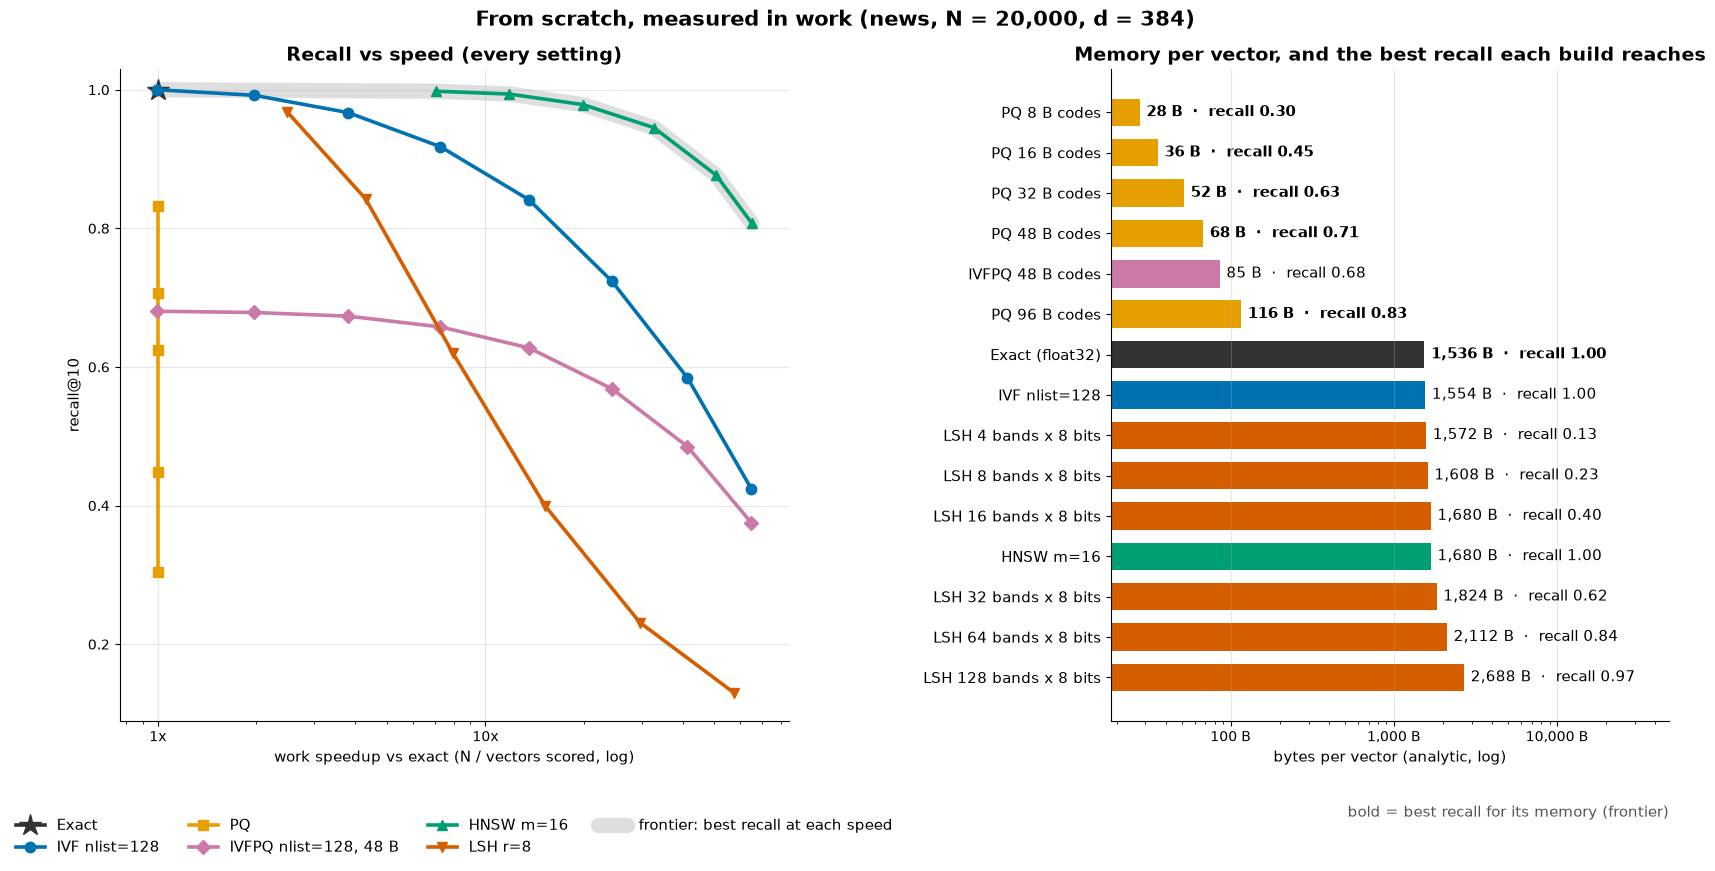

{'speed_axis': 'work_speedup',
 'n_settings': 34,
 'n_on_frontier': 26,
 'frontier_counts': {'exact': 1,
  'hnsw': 6,
  'ivf': 7,
  'ivfpq': 7,
  'lsh': 0,
  'pq': 5},
 'families_on_frontier': ['exact', 'hnsw', 'ivf', 'ivfpq', 'pq'],
 'fully_dominated': ['lsh'],
 'single_family_dominates': False}

In [4]:
work_front = pareto_mask(work_df, {"recall": "max", "work_speedup": "max", "nbytes": "min"})
work_report = dominance_report(work_df, "work_speedup")
fig = vis.plot_triangle(work_df, "work_speedup", "work speedup vs exact (N / vectors scored, log)",
                        f"From scratch, measured in work (news, N = {n:,}, d = {news.d})", K)
show(fig, "05_triangle_work")
cols = ["index", "params", "recall", "work", "work_speedup", "nbytes", "bytes_per_vector", "build_s"]
save_json("05_triangle_work", {"k": K, "n": n, "d": news.d, "rows": work_df.assign(on_frontier=work_front)[cols + ["on_frontier"]],
                               "dominance": work_report})
work_report

Reading the work chart, family by family:

- **HNSW** owns the recall-vs-speed frontier (the grey band, left): the highest recall for the
  least work. On the right panel its bar is *longer* than exact search's — it pays for that speed in
  memory.
- **IVF** is the runner-up on speed — for the same recall it scores several times more vectors
  than HNSW — but costs only a few bytes per vector over the raw floats (an id each, plus the
  centroids) and trains in a fraction of a second.
- **PQ** owns the recall-vs-memory frontier (bold labels, right): tens of times smaller, at a
  recall it cannot climb out of. Flat PQ scans every code, so its work speedup is 1 — its points stack up
  at the left edge of the speed panel.
- **IVFPQ** pulls both levers: nearly PQ's memory with IVF's skipping, capped at PQ's recall.
- **LSH** needs far more work for the same recall on these dense embeddings — the hashing
  approach of `hashing_101` is beaten by clustering and graphs here. (It still has its uses:
  no training, cheap inserts, and it shines on set similarity, where `hashing_101` applies it.)

The two panels have different owners — that is the triangle. The computed 3-D version (no other
setting at least as good on recall, speed *and* memory, and better on one) is the report printed
above: several families share the 3-D frontier, and no single family owns it.

## The compiled engines, in wall-clock time

The same families in faiss (`IndexFlatL2`, `IndexIVFFlat`, `IndexPQ`, `IndexIVFPQ`) and hnswlib,
on all 50,000 news vectors, every query timed one at a time on one thread. Speed is the speedup
over faiss's exact `IndexFlatL2` on the same machine. hnswlib is swept at three graph degrees.

In [5]:
from src.evaluation.speed import median_latency_ms
from src.reference.compare import FaissFlat, FaissIVF, FaissIVFPQ, FaissPQ, HnswlibHNSW

bench = S.bench
wc_common = {"dataset": "news", "seed": SEED, "threads": THREADS, "timed": True, "warmup": bench.warmup,
             "max_queries": bench.max_queries}
xb_all, gt_all = news.base, news.gt_ids
wc_rows = []
with pinned_threads(THREADS):
    flat = FaissFlat()
    flat_build = timed_build(flat, xb_all)
    exact_ms = median_latency_ms(flat, xq, K, warmup=bench.warmup, max_queries=bench.max_queries)
    wc_rows += sweep(flat, None, [], xq, gt_all, K, engine="faiss", build_params={}, build_s=flat_build,
                     exact_latency_ms=exact_ms, **wc_common)
    del flat

    ref = FaissIVF(nlist=ivf_cfg.nlist, kmeans_max_iter=ivf_cfg.kmeans_max_iter, seed=SEED)
    wc_rows += sweep(ref, "nprobe", ivf_cfg.nprobe_sweep, xq, gt_all, K, engine="faiss",
                     build_params={"nlist": ivf_cfg.nlist}, build_s=timed_build(ref, xb_all),
                     exact_latency_ms=exact_ms, **wc_common)

    for m in pq_cfg.n_subvectors_sweep:
        ref = FaissPQ(n_subvectors=m, nbits=pq_cfg.nbits)
        t0 = time.perf_counter()
        ref.train(xb_all[: pq_cfg.train_size])
        ref.add(xb_all)
        wc_rows += sweep(ref, None, [], xq, gt_all, K, engine="faiss", build_params={"n_subvectors": m},
                         build_s=time.perf_counter() - t0, exact_latency_ms=exact_ms, **wc_common)

    ref = FaissIVFPQ(nlist=S.ivfpq.nlist, n_subvectors=S.ivfpq.n_subvectors, nbits=pq_cfg.nbits, seed=SEED)
    t0 = time.perf_counter()
    ref.train(xb_all[: pq_cfg.train_size])
    ref.add(xb_all)
    wc_rows += sweep(ref, "nprobe", S.ivfpq.nprobe_sweep, xq, gt_all, K, engine="faiss",
                     build_params={"nlist": S.ivfpq.nlist, "n_subvectors": S.ivfpq.n_subvectors},
                     build_s=time.perf_counter() - t0, exact_latency_ms=exact_ms, **wc_common)

    for m in tri.hnswlib_m_sweep:
        ref = HnswlibHNSW(m=m, ef_construction=h.ef_construction, seed=SEED, threads=THREADS)
        wc_rows += sweep(ref, "ef_search", h.ef_search_sweep, xq, gt_all, K, engine="hnswlib",
                         build_params={"m": m, "ef_construction": h.ef_construction},
                         build_s=timed_build(ref, xb_all), exact_latency_ms=exact_ms, **wc_common)
wall_df = expand_params(to_frame(wc_rows))
print(f"faiss exact search: {exact_ms:.2f} ms per query on {news.n:,} vectors")

faiss exact search: 6.16 ms per query on 50,000 vectors


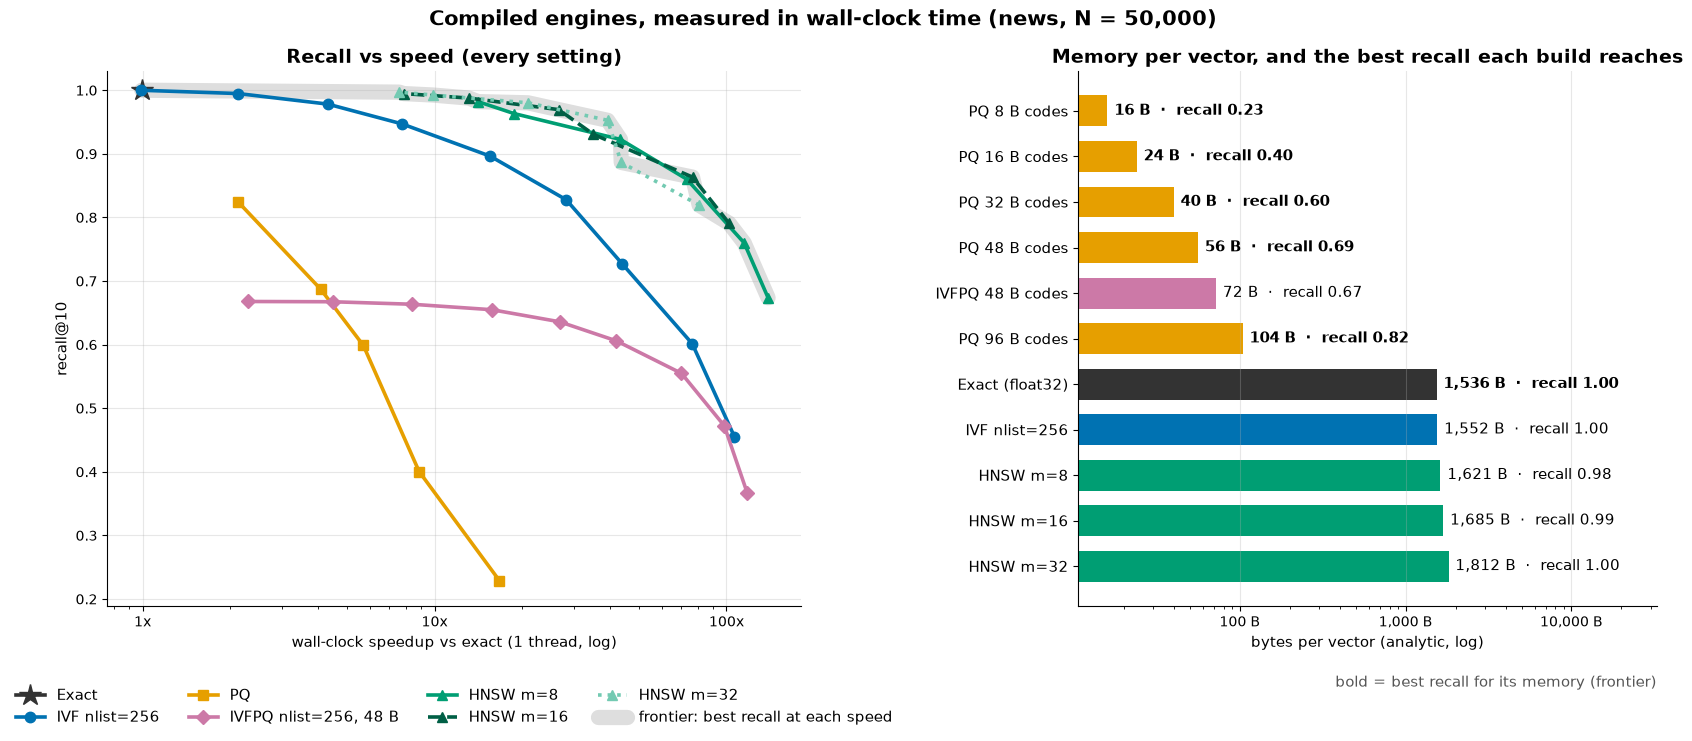

{'speed_axis': 'speedup_vs_exact',
 'n_settings': 42,
 'n_on_frontier': 40,
 'frontier_counts': {'exact': 1, 'hnsw': 18, 'ivf': 8, 'ivfpq': 8, 'pq': 5},
 'families_on_frontier': ['exact', 'hnsw', 'ivf', 'ivfpq', 'pq'],
 'fully_dominated': [],
 'single_family_dominates': False}

In [6]:
wall_front = pareto_mask(wall_df, {"recall": "max", "speedup_vs_exact": "max", "nbytes": "min"})
wall_report = dominance_report(wall_df, "speedup_vs_exact")
fig = vis.plot_triangle(wall_df, "speedup_vs_exact", "wall-clock speedup vs exact (1 thread, log)",
                        f"Compiled engines, measured in wall-clock time (news, N = {news.n:,})", K)
show(fig, "05_triangle_wallclock")
cols_wc = ["index", "engine", "params", "recall", "latency_ms", "qps", "speedup_vs_exact", "nbytes", "bytes_per_vector", "build_s"]
save_json("05_triangle_wallclock", {"k": K, "n": news.n, "d": news.d, "exact_latency_ms": exact_ms, "machine": MACHINE,
                                    "rows": wall_df.assign(on_frontier=wall_front)[cols_wc + ["on_frontier"]],
                                    "dominance": wall_report})
wall_report

The wall-clock chart tells the same story in real time. HNSW (hnswlib) reaches high recall at the
largest speedups, with more memory as `m` grows; IVF trails it; PQ and IVFPQ trade recall for an
index a fraction of the size. Several families own part of the frontier, and no single family
owns all of it.

## The cheapest way to reach a recall target

The triangle as a table: for each family, the fastest setting that reaches recall@10 ≥ 0.9, and
what it costs in memory and build time.

In [7]:
def cheapest(df, speed_col, target=0.9):
    out = []
    for fam, grp in df.groupby("index", sort=False):
        ok = grp[grp["recall"] >= target]
        if ok.empty:
            best = grp.loc[grp["recall"].idxmax()]
            out.append({"index": fam, "reaches_target": False, "params": best["params"], "recall": best["recall"],
                        "speed": best[speed_col], "bytes_per_vector": best["bytes_per_vector"], "build_s": best["build_s"]})
            continue
        best = ok.loc[ok[speed_col].idxmax()]
        out.append({"index": fam, "reaches_target": True, "params": best["params"], "recall": best["recall"],
                    "speed": best[speed_col], "bytes_per_vector": best["bytes_per_vector"], "build_s": best["build_s"]})
    return pd.DataFrame(out)

best_work = cheapest(work_df, "work_speedup")
best_wall = cheapest(wall_df, "speedup_vs_exact")
save_json("05_cheapest_at_recall_0.9", {"target": 0.9, "k": K, "work_scratch": best_work, "wallclock_compiled": best_wall})
print("from scratch (speed = work speedup):"); display(best_work.round(3))
print("compiled (speed = wall-clock speedup):"); display(best_wall.round(3))

from scratch (speed = work speedup):


,index,reaches_target,params,recall,speed,bytes_per_vector,build_s
0,exact,True,{},1.000,1.000,1536.000,0.013
1,ivf,True,"{""nlist"": 128, ""nprobe"": 16}",0.918,7.295,1553.830,0.341
2,pq,False,"{""n_subvectors"": 96}",0.832,1.000,115.661,21.146
3,ivfpq,False,"{""n_subvectors"": 48, ""nlist"": 128, ""nprobe"": 128}",0.680,0.994,85.491,11.455
4,hnsw,True,"{""ef_construction"": 64, ""ef_search"": 32, ""m"": 16}",0.945,32.701,1680.266,NaN
5,lsh,True,"{""bands"": 128, ""rows"": 8}",0.968,2.484,2688.000,0.508


compiled (speed = wall-clock speedup):


,index,reaches_target,params,recall,speed,bytes_per_vector,build_s
0,exact,True,{},1.000,0.993,1536.001,0.045
1,ivf,True,"{""nlist"": 256, ""nprobe"": 32}",0.947,7.735,1551.908,10.719
2,pq,False,"{""n_subvectors"": 96}",0.824,2.127,103.866,57.345
3,ivfpq,False,"{""n_subvectors"": 48, ""nlist"": 256, ""nprobe"": 256}",0.668,2.290,71.773,6.996
4,hnsw,True,"{""ef_construction"": 64, ""ef_search"": 64, ""m"": 8}",0.923,43.353,1621.233,7.136


In [8]:
summary = {
    "work_families_on_frontier": work_report["families_on_frontier"],
    "work_fully_dominated": work_report["fully_dominated"],
    "wall_families_on_frontier": wall_report["families_on_frontier"],
    "wall_fully_dominated": wall_report["fully_dominated"],
    "single_family_dominates_work": work_report["single_family_dominates"],
    "single_family_dominates_wall": wall_report["single_family_dominates"],
    "runtime_s": time.perf_counter() - NB_START,
}
save_json("05_summary", summary)
fmt = lambda xs: ", ".join(vis.INDEX_NAMES[x] for x in xs) or "none"
hw = best_wall.set_index("index")
display(Markdown(f'''
### What this bought you, and what it cost

- **The verdict is a shape, not a winner.** On the work chart the Pareto frontier is shared by
  {fmt(summary["work_families_on_frontier"])}; on the wall-clock chart by
  {fmt(summary["wall_families_on_frontier"])}. Fully dominated: {fmt(summary["work_fully_dominated"])}
  (work) and {fmt(summary["wall_fully_dominated"])} (wall-clock).
- **To reach recall@10 ≥ 0.9 in wall-clock time:** HNSW is the fastest
  ({hw.loc["hnsw", "speed"]:.0f}x exact, {hw.loc["hnsw", "bytes_per_vector"]:.0f} B/vector); IVF gets
  {hw.loc["ivf", "speed"]:.0f}x for {hw.loc["ivf", "bytes_per_vector"]:.0f} B/vector; the PQ family cannot
  get there at these code sizes — it is the corner you pick when memory, not recall, is the hard limit.
- **What a vector database does:** exactly this — it picks a family and a setting on these curves.
  Knowing the triangle is how you choose that point instead of inheriting it.
'''))
print(f"notebook runtime: {summary['runtime_s']:.0f} s")


### What this bought you, and what it cost

- **The verdict is a shape, not a winner.** On the work chart the Pareto frontier is shared by
  Exact, HNSW, IVF, IVFPQ, PQ; on the wall-clock chart by
  Exact, HNSW, IVF, IVFPQ, PQ. Fully dominated: LSH
  (work) and none (wall-clock).
- **To reach recall@10 ≥ 0.9 in wall-clock time:** HNSW is the fastest
  (43x exact, 1621 B/vector); IVF gets
  8x for 1552 B/vector; the PQ family cannot
  get there at these code sizes — it is the corner you pick when memory, not recall, is the hard limit.
- **What a vector database does:** exactly this — it picks a family and a setting on these curves.
  Knowing the triangle is how you choose that point instead of inheriting it.


notebook runtime: 308 s
